In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

In [13]:
from sklearn.datasets import load_breast_cancer

# Load dataset
data = load_breast_cancer()
X = data.data

# Normalize dataset
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

print("Dataset shape:", X.shape)

Dataset shape: (569, 30)


In [14]:
input_layer = Input(shape=(X.shape[1],))

encoded = Dense(16, activation='relu')(input_layer)
encoded = Dense(8, activation='relu')(encoded)

In [15]:
decoded = Dense(16, activation='relu')(encoded)
decoded = Dense(X.shape[1], activation='sigmoid')(decoded)

autoencoder = Model(input_layer, decoded)

In [16]:
# Compile the model
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Train the model
history = autoencoder.fit(
    X, X,
    epochs=30,
    batch_size=32,
    validation_split=0.2
)

# Evaluate the model
loss, mae = autoencoder.evaluate(X, X)

print("Test Loss:", loss)
print("Test MAE:", mae)

Epoch 1/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 0.0933 - mae: 0.2753 - val_loss: 0.0928 - val_mae: 0.2772
Epoch 2/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0828 - mae: 0.2583 - val_loss: 0.0810 - val_mae: 0.2577
Epoch 3/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0698 - mae: 0.2350 - val_loss: 0.0655 - val_mae: 0.2284
Epoch 4/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0546 - mae: 0.2038 - val_loss: 0.0490 - val_mae: 0.1918
Epoch 5/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0421 - mae: 0.1731 - val_loss: 0.0379 - val_mae: 0.1617
Epoch 6/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0356 - mae: 0.1532 - val_loss: 0.0327 - val_mae: 0.1451
Epoch 7/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0329 - mae: 0.1437 - val_loss: 0.0305 - val_mae: 0.1380
Epoch 8/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0314 - mae: 0.1392 - val_loss: 0.0293 - val_mae: 0.1348
Epoch 9/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0302 - mae:

In [29]:
# Generate reconstructed output
predictions = autoencoder.predict(X)

# Calculate reconstruction error
error = np.mean(np.square(X - predictions), axis=1)

# Calculate threshold
threshold = np.percentile(error, 95)

# Detect anomalies
anomalies = error > threshold

print("Reconstruction Error:", error)
print("Threshold:", threshold)
print("Total Anomalies:", np.sum(anomalies))

18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Reconstruction Error: [0.02577276 0.0077346  0.00370718 0.0981502  0.01030055 0.0170751
 0.00328975 0.01056551 0.01635637 0.06554465 0.00742166 0.00457977
 0.02879978 0.00550756 0.02419587 0.01768864 0.00361244 0.0082729
 0.00806016 0.00328258 0.00463814 0.00493253 0.02161879 0.01176635
 0.00869404 0.02221702 0.01864055 0.00480585 0.01010553 0.00406853
 0.00350936 0.01873036 0.0055977  0.0085739  0.00858076 0.00789238
 0.00390274 0.00782833 0.02103492 0.01049877 0.00479809 0.01479426
 0.01874955 0.00440911 0.00656494 0.00808117 0.0031104  0.01091945
 0.00325018 0.00390047 0.00307726 0.00445395 0.00140529 0.00645011
 0.00446278 0.00266089 0.00429089 0.00487117 0.00463581 0.01014574
 0.01864402 0.01479526 0.01610195 0.01362701 0.0085019  0.00676486
 0.00895642 0.00299804 0.06656339 0.00208733 0.00904045 0.04621709
 0.01066498 0.00480608 0.00104207 0.00515102 0.02042188 0.01164499
 0.05099441 0.00066595 0.01019726 0.0069186  0.01754733 0.01639281
 0.

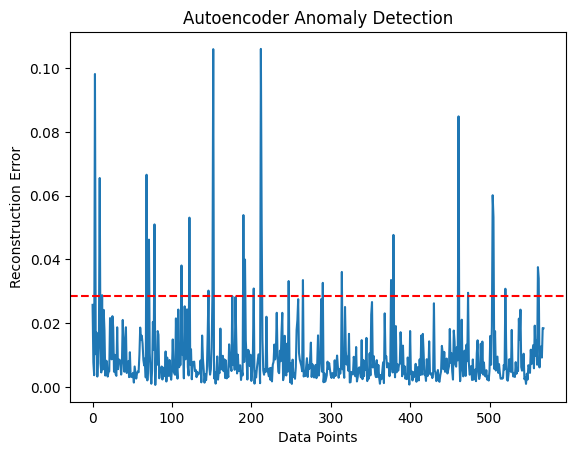

In [30]:
plt.plot(error)
plt.axhline(threshold, color='red', linestyle='--')

plt.xlabel("Data Points")
plt.ylabel("Reconstruction Error")
plt.title("Autoencoder Anomaly Detection")
plt.show()

In [31]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
y_pred = (error > threshold).astype(int)
y_true = (data.target == 0).astype(int)

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))

Accuracy: 0.6256590509666081
Precision: 0.4827586206896552
Recall: 0.0660377358490566
